# Grid vs. Random vs. Bayesiano: O Confronto (The Showdown)

*Complemento de* **Mastering CatBoost — Pro Edition**, Capítulo 4: Tuning & Diagnostics as System Control, §4.1 (Visão Geral) e §4.2 (A Filosofia de Ajuste / The Tuning Philosophy).

O Capítulo 4 começa classificando o Grid Search sobre "um saco de botões desconexos" como ineficiente e perigoso. Este notebook coloca essa afirmação à prova sob condições controladas: três estratégias de busca, o **mesmo orçamento** (24 ajustes de modelo cada), os **mesmos dados**, o **mesmo espaço de busca** e a **mesma disciplina de sementes aleatórias (seeds)**. O notebook computa a comparação — nenhum resultado é presumido antecipadamente.

In [1]:
# %pip install -q catboost==1.2.10 scikit-learn==1.6.1 numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0 optuna==4.2.1

import itertools
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from catboost import CatBoostClassifier

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

## 1. Condições experimentais fixas

- **Orçamento de avaliação:** 24 ajustes de desenvolvimento com parada antecipada (*early stopping*) por estratégia. O número de árvores retidas e o tempo de execução (*wall time*) podem variar.
- **Limites (Bounds):** todas as estratégias utilizam os mesmos limites declarados para os parâmetros, mas o Grid faz amostragens em pontos de grade discretos e espaçados, enquanto o Random e o TPE amostram domínios contínuos/logarítmicos.
- **Dados:** busca nos conjuntos de treino/validação; congela o campeão de cada estratégia antes da avaliação final.
- **Comparação:** contagem igual de avaliações não significa custo computacional igual. Relate tanto o número de ajustes quanto o tempo de relógio (*wall time*).

In [2]:
from sklearn.datasets import make_classification
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=8_000, n_features=20, n_informative=9,
                           n_redundant=4, flip_y=0.1, random_state=RANDOM_SEED)
X = X.astype(np.float32)
X_tr, X_rest, y_tr, y_rest = train_test_split(X, y, test_size=0.4, random_state=RANDOM_SEED, stratify=y)
X_va, X_te, y_va, y_te = train_test_split(X_rest, y_rest, test_size=0.5, random_state=RANDOM_SEED, stratify=y_rest)

BUDGET = 24

def evaluate(lr, depth, l2):
    m = CatBoostClassifier(iterations=400, learning_rate=lr, depth=int(depth), l2_leaf_reg=l2,
                           eval_metric="AUC", random_seed=RANDOM_SEED, verbose=0,
                           allow_writing_files=False)
    m.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=40, use_best_model=True)
    return m.get_best_score()["validation"]["AUC"], m

print(f"budget: {BUDGET} evaluations per strategy")

budget: 24 evaluations per strategy


## 2. Estratégia A — Busca em Grade (Grid Search)

Uma grade de 3 × 4 × 2 = 24 pontos. Note o dilema intrínseco: com um orçamento fixo, cada valor adicional testado para um hiperparâmetro "rouba" resolução dos demais, e parâmetros contínuos acabam recebendo apenas alguns poucos níveis discretizados.

In [3]:
grid_lr = [0.03, 0.1, 0.3]
grid_depth = [4, 6, 8, 10]
grid_l2 = [1.0, 9.0]

grid_trials = []
t0 = time.perf_counter()
for lr, d, l2 in itertools.product(grid_lr, grid_depth, grid_l2):
    auc, _ = evaluate(lr, d, l2)
    grid_trials.append({"lr": lr, "depth": d, "l2": l2, "valid_auc": auc})
grid_time = time.perf_counter() - t0
grid_df = pd.DataFrame(grid_trials)
grid_best = grid_df.loc[grid_df.valid_auc.idxmax()]
print(f"grid: best valid AUC {grid_best.valid_auc:.4f} at lr={grid_best.lr}, "
      f"depth={int(grid_best.depth)}, l2={grid_best.l2} | {grid_time:.0f}s")

grid: best valid AUC 0.9588 at lr=0.1, depth=8, l2=1.0 | 65s


## 3. Estratégia B — Busca Aleatória (Random Search)

24 sorteios independentes a partir do espaço *contínuo*. A clássica vantagem do Random Search (argumento de Bergstra & Bengio): quando apenas algumas dimensões realmente importam, pontos aleatórios fornecem 24 valores distintos ao longo de **cada** eixo, enquanto a grade forneceu apenas 3 valores para `learning_rate`.

In [4]:
rng = np.random.RandomState(RANDOM_SEED)
random_trials = []
t0 = time.perf_counter()
for _ in range(BUDGET):
    lr = float(np.exp(rng.uniform(np.log(0.02), np.log(0.3))))
    d = int(rng.randint(4, 11))
    l2 = float(np.exp(rng.uniform(np.log(0.5), np.log(30))))
    auc, _ = evaluate(lr, d, l2)
    random_trials.append({"lr": lr, "depth": d, "l2": l2, "valid_auc": auc})
random_time = time.perf_counter() - t0
random_df = pd.DataFrame(random_trials)
random_best = random_df.loc[random_df.valid_auc.idxmax()]
print(f"random: best valid AUC {random_best.valid_auc:.4f} at lr={random_best.lr:.3f}, "
      f"depth={int(random_best.depth)}, l2={random_best.l2:.2f} | {random_time:.0f}s")

random: best valid AUC 0.9603 at lr=0.047, depth=9, l2=1.17 | 108s


## 4. Estratégia C — Busca Bayesiana (Optuna TPE)

Mesmo espaço, mesmo orçamento, mas cada novo ponto é *proposto* a partir de um modelo dos resultados anteriores: o TPE divide as tentativas observadas em grupos "bons" e "ruins" e amostra onde a densidade do grupo bom predomina. As primeiras tentativas são essencialmente aleatórias (fase de inicialização/startup); em seguida, a adaptação entra em ação — observe isso no gráfico de trajetória.

In [5]:
def objective(trial):
    lr = trial.suggest_float("lr", 0.02, 0.3, log=True)
    d = trial.suggest_int("depth", 4, 10)
    l2 = trial.suggest_float("l2", 0.5, 30.0, log=True)
    auc, _ = evaluate(lr, d, l2)
    return auc

study = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED))
t0 = time.perf_counter()
study.optimize(objective, n_trials=BUDGET)
tpe_time = time.perf_counter() - t0
tpe_df = study.trials_dataframe()
print(f"TPE: best valid AUC {study.best_value:.4f} at {study.best_params} | {tpe_time:.0f}s")

TPE: best valid AUC 0.9597 at {'lr': 0.025333961458276943, 'depth': 8, 'l2': 3.663480740496467} | 107s


## 5. A comparação — computada, não apenas afirmada

In [6]:
summary = pd.DataFrame([
    {"strategy": "grid",   "best_valid_auc": round(grid_df.valid_auc.max(), 4),
     "mean_valid_auc": round(grid_df.valid_auc.mean(), 4), "wall_s": round(grid_time)},
    {"strategy": "random", "best_valid_auc": round(random_df.valid_auc.max(), 4),
     "mean_valid_auc": round(random_df.valid_auc.mean(), 4), "wall_s": round(random_time)},
    {"strategy": "TPE",    "best_valid_auc": round(study.best_value, 4),
     "mean_valid_auc": round(tpe_df["value"].mean(), 4), "wall_s": round(tpe_time)},
])
summary

,strategy,best_valid_auc,mean_valid_auc,wall_s
0,grid,0.9588,0.9572,65
1,random,0.9603,0.9578,108
2,TPE,0.9597,0.9575,107


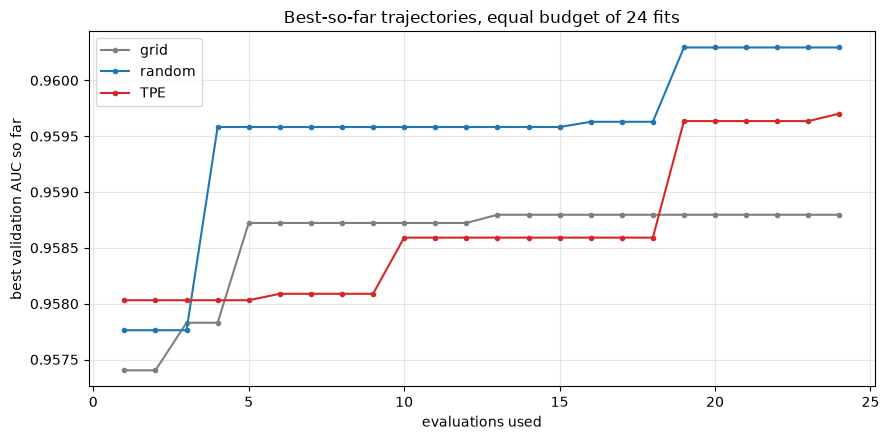

In [7]:
plt.figure(figsize=(9, 4.5))
for name, vals, color in [("grid", grid_df.valid_auc.values, "tab:gray"),
                          ("random", random_df.valid_auc.values, "tab:blue"),
                          ("TPE", tpe_df["value"].values, "tab:red")]:
    best_so_far = np.maximum.accumulate(vals)
    plt.plot(range(1, len(vals) + 1), best_so_far, "-o", ms=3, label=name, color=color)
plt.xlabel("avaliações utilizadas"); plt.ylabel("melhor AUC de validação até o momento")
plt.title(f"Trajetórias do melhor resultado até o momento (orçamento igual de {BUDGET} ajustes)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [8]:
# Avaliação única no conjunto de teste para o campeão de cada estratégia (tocar no conjunto de teste apenas uma vez, ao final).
champions = {
    "grid": (grid_best.lr, grid_best.depth, grid_best.l2),
    "random": (random_best.lr, random_best.depth, random_best.l2),
    "TPE": (study.best_params["lr"], study.best_params["depth"], study.best_params["l2"]),
}
rows = []
for name, (lr, d, l2) in champions.items():
    _, m = evaluate(lr, d, l2)
    rows.append({"strategy": name,
                 "test_AUC": round(roc_auc_score(y_te, m.predict_proba(X_te)[:, 1]), 4)})
pd.DataFrame(rows)

,strategy,test_AUC
0,grid,0.9611
1,random,0.9612
2,TPE,0.9612


### Como interpretar os resultados

Compare as trajetórias do "melhor até o momento" (*best-so-far*), os valores de validação selecionados, o tempo total de execução e a repetição com diferentes sementes de busca. A média das tentativas não é o objetivo da busca e não precisa necessariamente favorecer o TPE. Grid, Random ou TPE podem vencer em uma execução finita com ruído; a grade grosseira também explora um suporte discreto diferente dentro dos limites compartilhados.

## Principais Aprendizados (Takeaways)

- O Grid aloca avaliações em uma grade declarada; Random e TPE amostram domínios contínuos mais amplos.
- Nenhum método tem garantia de dominar em dimensões efetivas baixas ou em um orçamento fixo pré-determinado.
- A adaptação do TPE pode ajudar ou prejudicar em execuções finitas; poda (*pruning*) e parada antecipada (*early stopping*) alteram os custos de tempo de máquina.
- Congele os candidatos antes da avaliação única no conjunto de teste e compare as margens com a variabilidade das sementes (*seeds*).

## Exercícios

**Exercício 1 - Replicação.** Repita todas as estratégias estocásticas variando as sementes de busca (*search seeds*) e reporte a distribuição de classificação (*ranking*).

**Exercício 2 - Escalonamento de orçamento.** Compare orçamentos de 8, 24 e 48 avaliações e tempo de relógio. Reporte as trajetórias reais; não presuma uma vantagem crescente automática para o TPE.

**Exercício 3 - Adicione uma dimensão condicional.** Compare suportes e orçamentos computacionais explicitamente. Uma dimensionalidade maior motiva alternativas a grades exaustivas, mas não garante a vitória do Random ou do TPE.

### Soluções ocultas

<details><summary>Solução</summary>

**Exercício 1.** Execute cada busca estocástica por pelo menos dez sementes de amostragem. Para cada execução, armazene o melhor valor de validação, os parâmetros selecionados, as avaliações concluídas, o tempo de execução e a classificação entre os métodos. Relate o número de vitórias e as diferenças de pontuação pareadas com intervalos de confiança; não utilize o valor médio das tentativas como critério de seleção.

</details>

<details><summary>Solução</summary>

**Exercício 2.** Com orçamentos de 8, 24 e 48 avaliações, reconstrua as trajetórias de validação do "melhor até o momento" a partir da ordem dos ensaios e plote separadamente o melhor resultado contra o tempo de execução acumulado. A parada antecipada faz com que contagens iguais de avaliações tenham custos diferentes, portanto forneça ambas as visualizações. Compare as distribuições das sementes em cada orçamento em vez de se basear em uma única trajetória afortunada.

</details>

<details><summary>Solução</summary>

**Exercício 3.** Adicione o parâmetro condicional apenas no ramo onde ele é válido e documente o suporte real de cada método: pontos da grade, distribuições aleatórias e distribuições do TPE. Mantenha o avaliador de validação fixo, compare tanto a contagem de avaliações quanto o tempo de relógio, e relate a cobertura do ramo condicional junto com a qualidade selecionada.

</details>